# Evaluasi
Analisis dilakukan pada data validation menggunakan prediksi yang disimpan oleh `02_training.ipynb`. Notebook ini dapat dijalankan tanpa GPU. Grad-CAM membutuhkan file checkpoint di folder `checkpoint/`.

## 0. Setup

In [4]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Violita-archive/document-image-classification.git"
REPO_NAME = "document-image-classification"

if Path("/kaggle/working").exists():
    ROOT = Path("/kaggle/working") / REPO_NAME
    if ROOT.exists():
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    try:
        import timm
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm"], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Root:", ROOT)

Root: d:\KULIAH\sem 5\Supervised ML\Asdos\kaggle_2\document-image-classification


In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display
from PIL import Image

from src.dataset import resolve_image_path
from src.evaluate import evaluation_report, plot_confusion_matrix, top_confusions
from src.gradcam import GradCAM, get_target_layer
from src.model import load_checkpoint
from src.transforms import get_eval_transforms, to_hw
from src.utils import CLASS_NAMES, load_config, resolve_data_dir

FIG_DIR, METRIC_DIR = Path("results/figures"), Path("results/metrics")
DATA_DIR = resolve_data_dir(load_config("configs/config.yaml")["data_dir"])
FINAL, BASE, CAM_MODEL = "ensemble", "baseline_resnet18", "convnext_tiny_512"

pred = pd.read_csv(METRIC_DIR / f"{FINAL}_val_predictions.csv")
pred_base = pd.read_csv(METRIC_DIR / f"{BASE}_val_predictions.csv")
pred["path"] = [resolve_image_path(DATA_DIR, f) for f in pred["filename"]]
print(f"Jumlah data validation: {len(pred):,}")

c:\Users\zerohack\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Jumlah data validation: 3,196


## 1. Ringkasan eksperimen

In [6]:
experiments = pd.read_csv(METRIC_DIR / "experiments.csv")
display(experiments)

,eksperimen,model,input,epoch_dijalankan,epoch_terbaik,train_acc,val_acc,val_loss,selisih_train_val,menit
0,baseline_resnet18,resnet18,224x224,5.0,5.0,0.856547,0.828536,0.586071,0.028011,11.948228
1,convnext_tiny_384,convnext_tiny,384x384,10.0,9.0,0.991375,0.886733,0.897150,0.104642,67.284508
2,convnext_tiny_512,convnext_tiny,512x384,12.0,11.0,0.979134,0.883292,0.916774,0.095842,108.558545
3,ensemble,convnext_tiny_384 + convnext_tiny_512,-,NaN,NaN,NaN,0.892365,NaN,NaN,175.843054


## 2. Metrik per kelas

In [7]:
acc, report = evaluation_report(pred["label"], pred["pred"])
acc_b, report_b = evaluation_report(pred_base["label"], pred_base["pred"])
print(f"Akurasi validation  final: {acc:.4f} | baseline: {acc_b:.4f}")

per_class = report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]].copy()
per_class["f1_baseline"] = report_b.loc[CLASS_NAMES, "f1-score"]
per_class = per_class.sort_values("f1-score")
per_class.to_csv(METRIC_DIR / "classification_report.csv")
display(per_class.style.format("{:.4f}", subset=["precision", "recall", "f1-score", "f1_baseline"])
        .background_gradient(cmap="RdYlGn", subset=["f1-score"]))

Akurasi validation  final: 0.8924 | baseline: 0.8285


,precision,recall,f1-score,support,f1_baseline
form,0.7500,0.7650,0.7574,200.000000,0.6375
scientific_report,0.7811,0.7850,0.7830,200.000000,0.6734
presentation,0.7953,0.8593,0.8261,199.000000,0.7222
questionnaire,0.8674,0.8051,0.8351,195.000000,0.7671
budget,0.8592,0.8806,0.8698,201.000000,0.7476
news_article,0.8989,0.8622,0.8802,196.000000,0.8311
advertisement,0.8654,0.9091,0.8867,198.000000,0.8416
letter,0.9211,0.8883,0.9044,197.000000,0.8571
invoice,0.9175,0.8990,0.9082,198.000000,0.8579
specification,0.9231,0.9091,0.9160,198.000000,0.8743


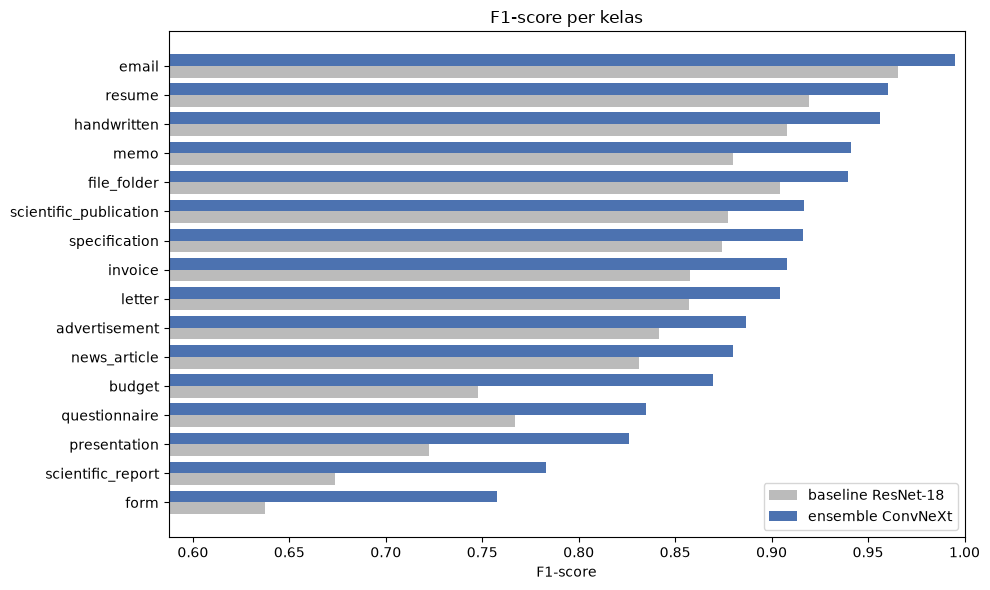

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(per_class))
ax.barh(y - 0.2, per_class["f1_baseline"], 0.4, label="baseline ResNet-18", color="#BBBBBB")
ax.barh(y + 0.2, per_class["f1-score"], 0.4, label="ensemble ConvNeXt", color="#4C72B0")
ax.set_yticks(y, per_class.index)
ax.set(xlabel="F1-score", title="F1-score per kelas", xlim=(per_class[["f1-score", "f1_baseline"]].min().min() - 0.05, 1))
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "f1_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Confusion matrix

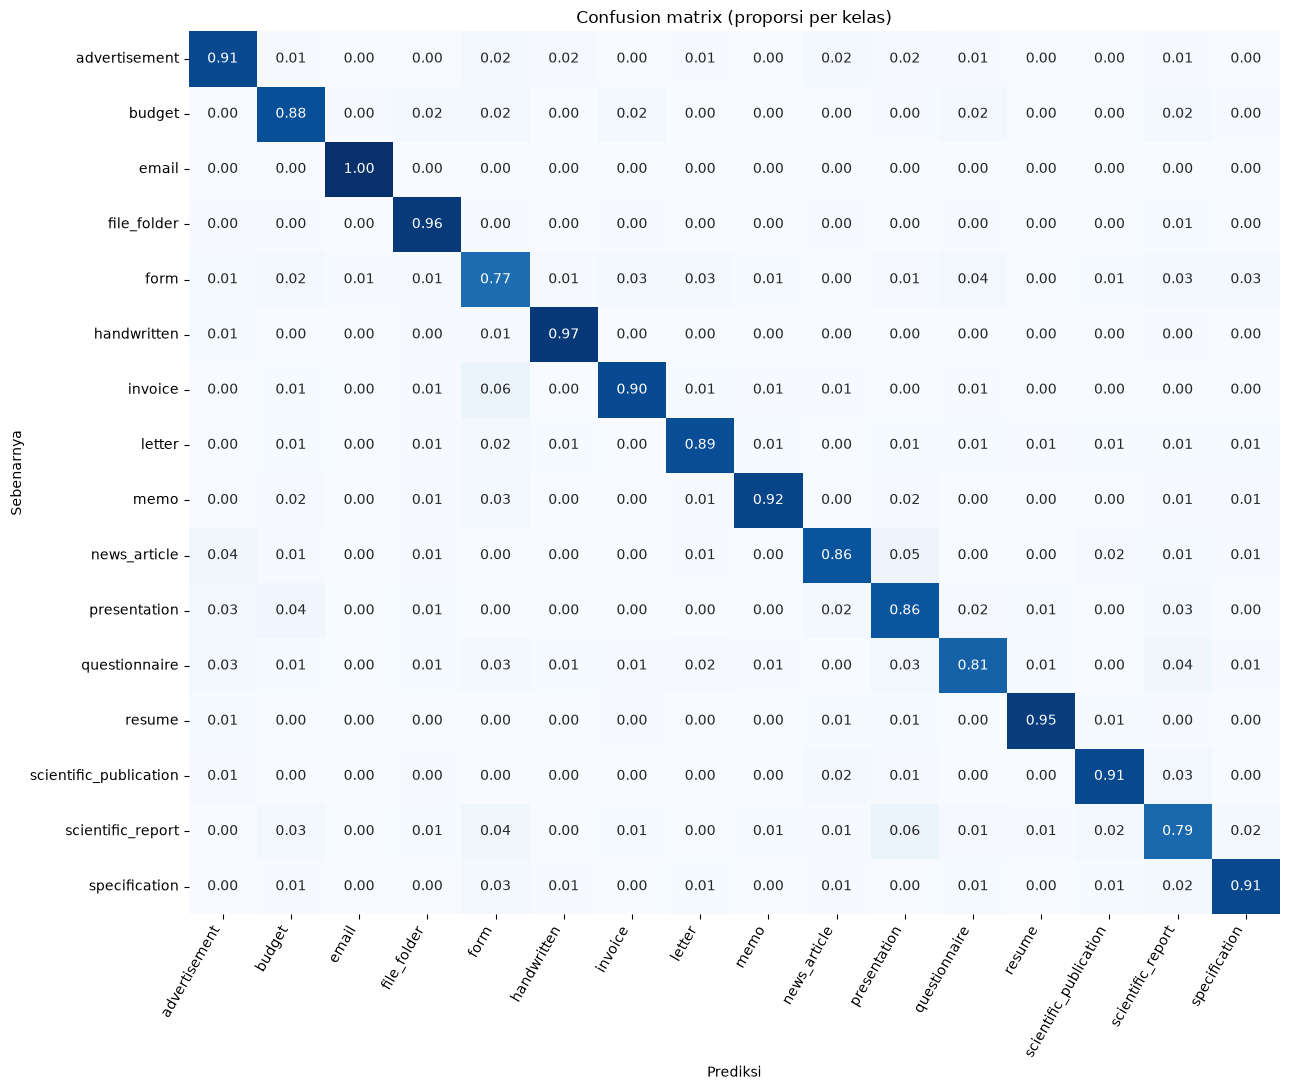

In [9]:
cm = plot_confusion_matrix(pred["label"], pred["pred"], normalize=True, save_path=FIG_DIR / "confusion_matrix.png")

In [10]:
conf_pairs = top_confusions(pred["label"], pred["pred"], k=10)
display(conf_pairs)

,sebenarnya,prediksi,jumlah
0,invoice,form,12
1,scientific_report,presentation,11
2,news_article,presentation,10
3,scientific_report,form,8
4,questionnaire,scientific_report,8
5,news_article,advertisement,8
6,form,questionnaire,7
7,scientific_publication,scientific_report,7
8,presentation,budget,7
9,questionnaire,presentation,6


## 4. Tingkat keyakinan prediksi

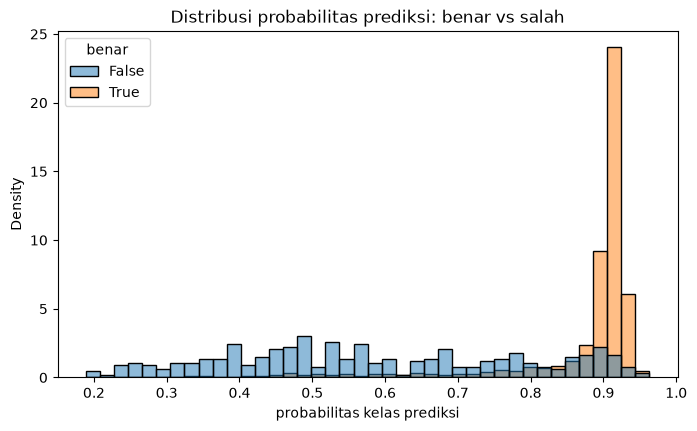

,jumlah,akurasi
confidence,,
"(0.0, 0.5]",229,0.388646
"(0.5, 0.7]",233,0.583691
"(0.7, 0.9]",793,0.894073
"(0.9, 1.0]",1941,0.988150


In [11]:
pred["benar"] = pred["label"] == pred["pred"]
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=pred, x="confidence", hue="benar", bins=40, stat="density", common_norm=False, ax=ax)
ax.set(title="Distribusi probabilitas prediksi: benar vs salah", xlabel="probabilitas kelas prediksi")
plt.savefig(FIG_DIR / "confidence_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

bins = pd.cut(pred["confidence"], [0, 0.5, 0.7, 0.9, 1.0])
display(pred.groupby(bins, observed=True)["benar"].agg(["count", "mean"]).rename(columns={"count": "jumlah", "mean": "akurasi"}))

## 5. Contoh prediksi salah
Diambil kesalahan dengan probabilitas tertinggi, yaitu kasus ketika model yakin namun keliru.

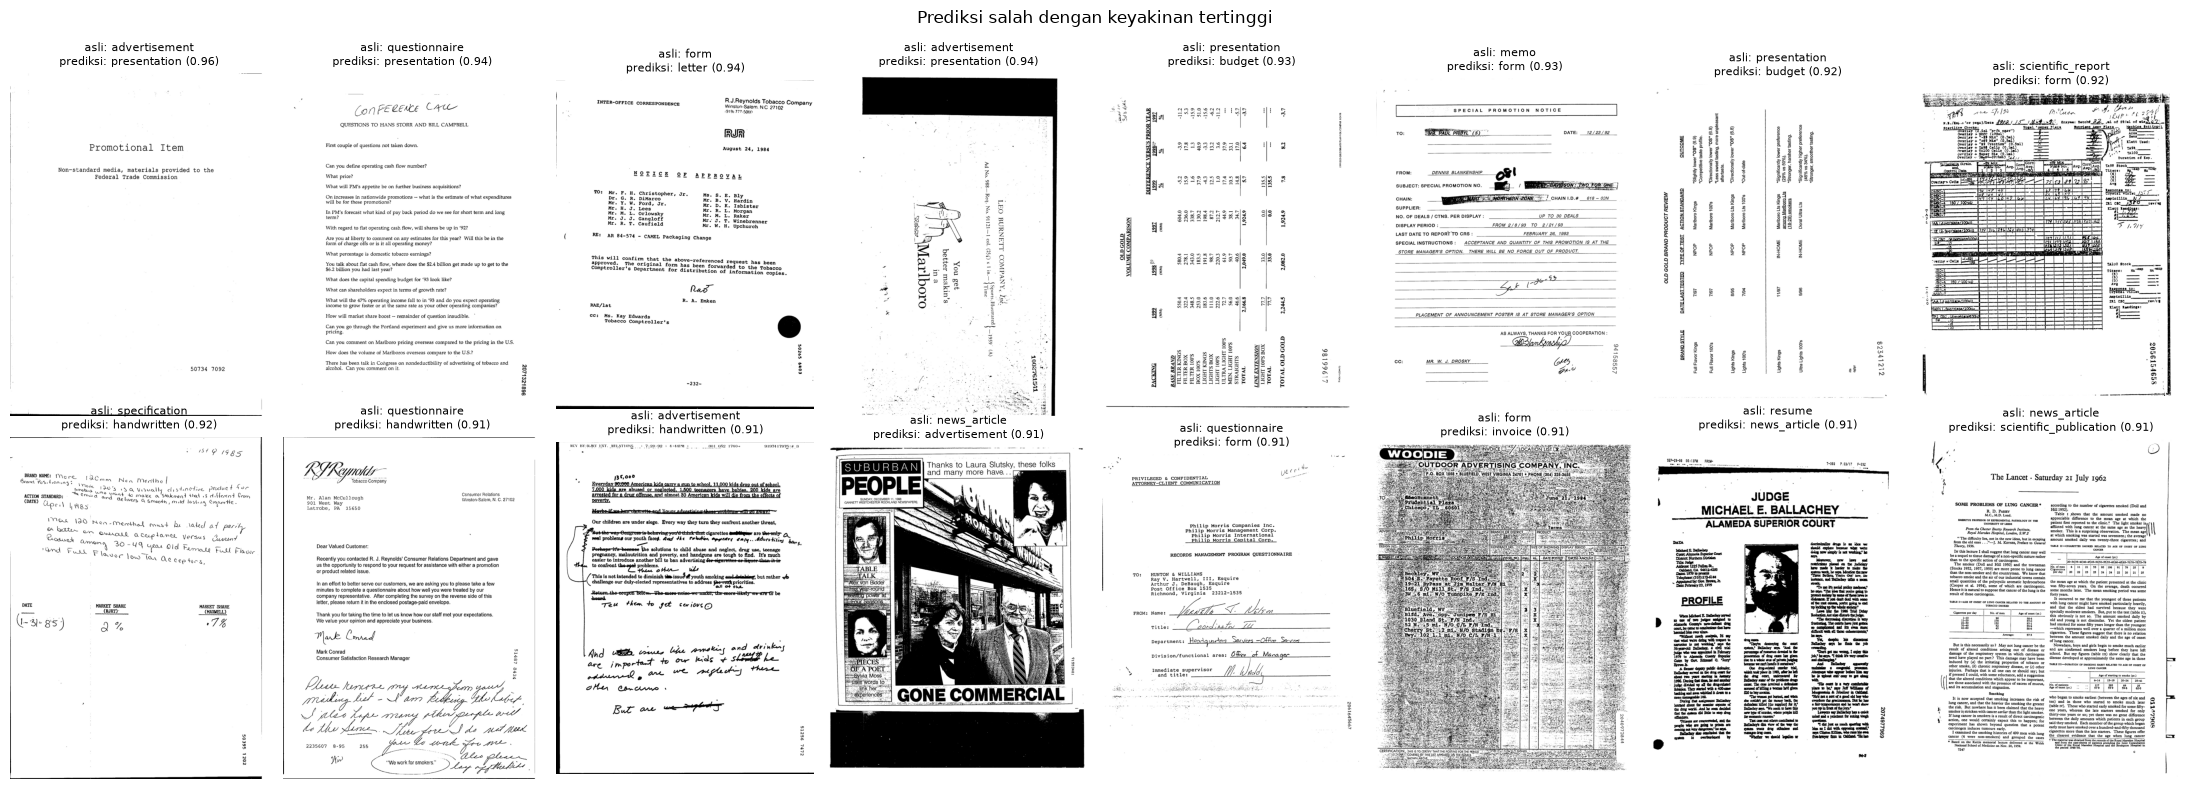

In [12]:
wrong = pred[~pred["benar"]].sort_values("confidence", ascending=False).head(16)
fig, axes = plt.subplots(2, 8, figsize=(22, 8))
for ax, (_, r) in zip(axes.ravel(), wrong.iterrows()):
    with Image.open(r["path"]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(f"asli: {CLASS_NAMES[r['label']]}\nprediksi: {CLASS_NAMES[r['pred']]} ({r['confidence']:.2f})", fontsize=8)
    ax.axis("off")
plt.suptitle("Prediksi salah dengan keyakinan tertinggi")
plt.tight_layout()
plt.savefig(FIG_DIR / "misclassified_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Grad-CAM
Area merah menunjukkan bagian gambar yang paling berpengaruh terhadap prediksi.

d:\KULIAH\sem 5\Supervised ML\Asdos\kaggle_2\document-image-classification\src\gradcam.py:71: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  return cam.cpu().numpy(), class_idx, float(prob[0, class_idx])


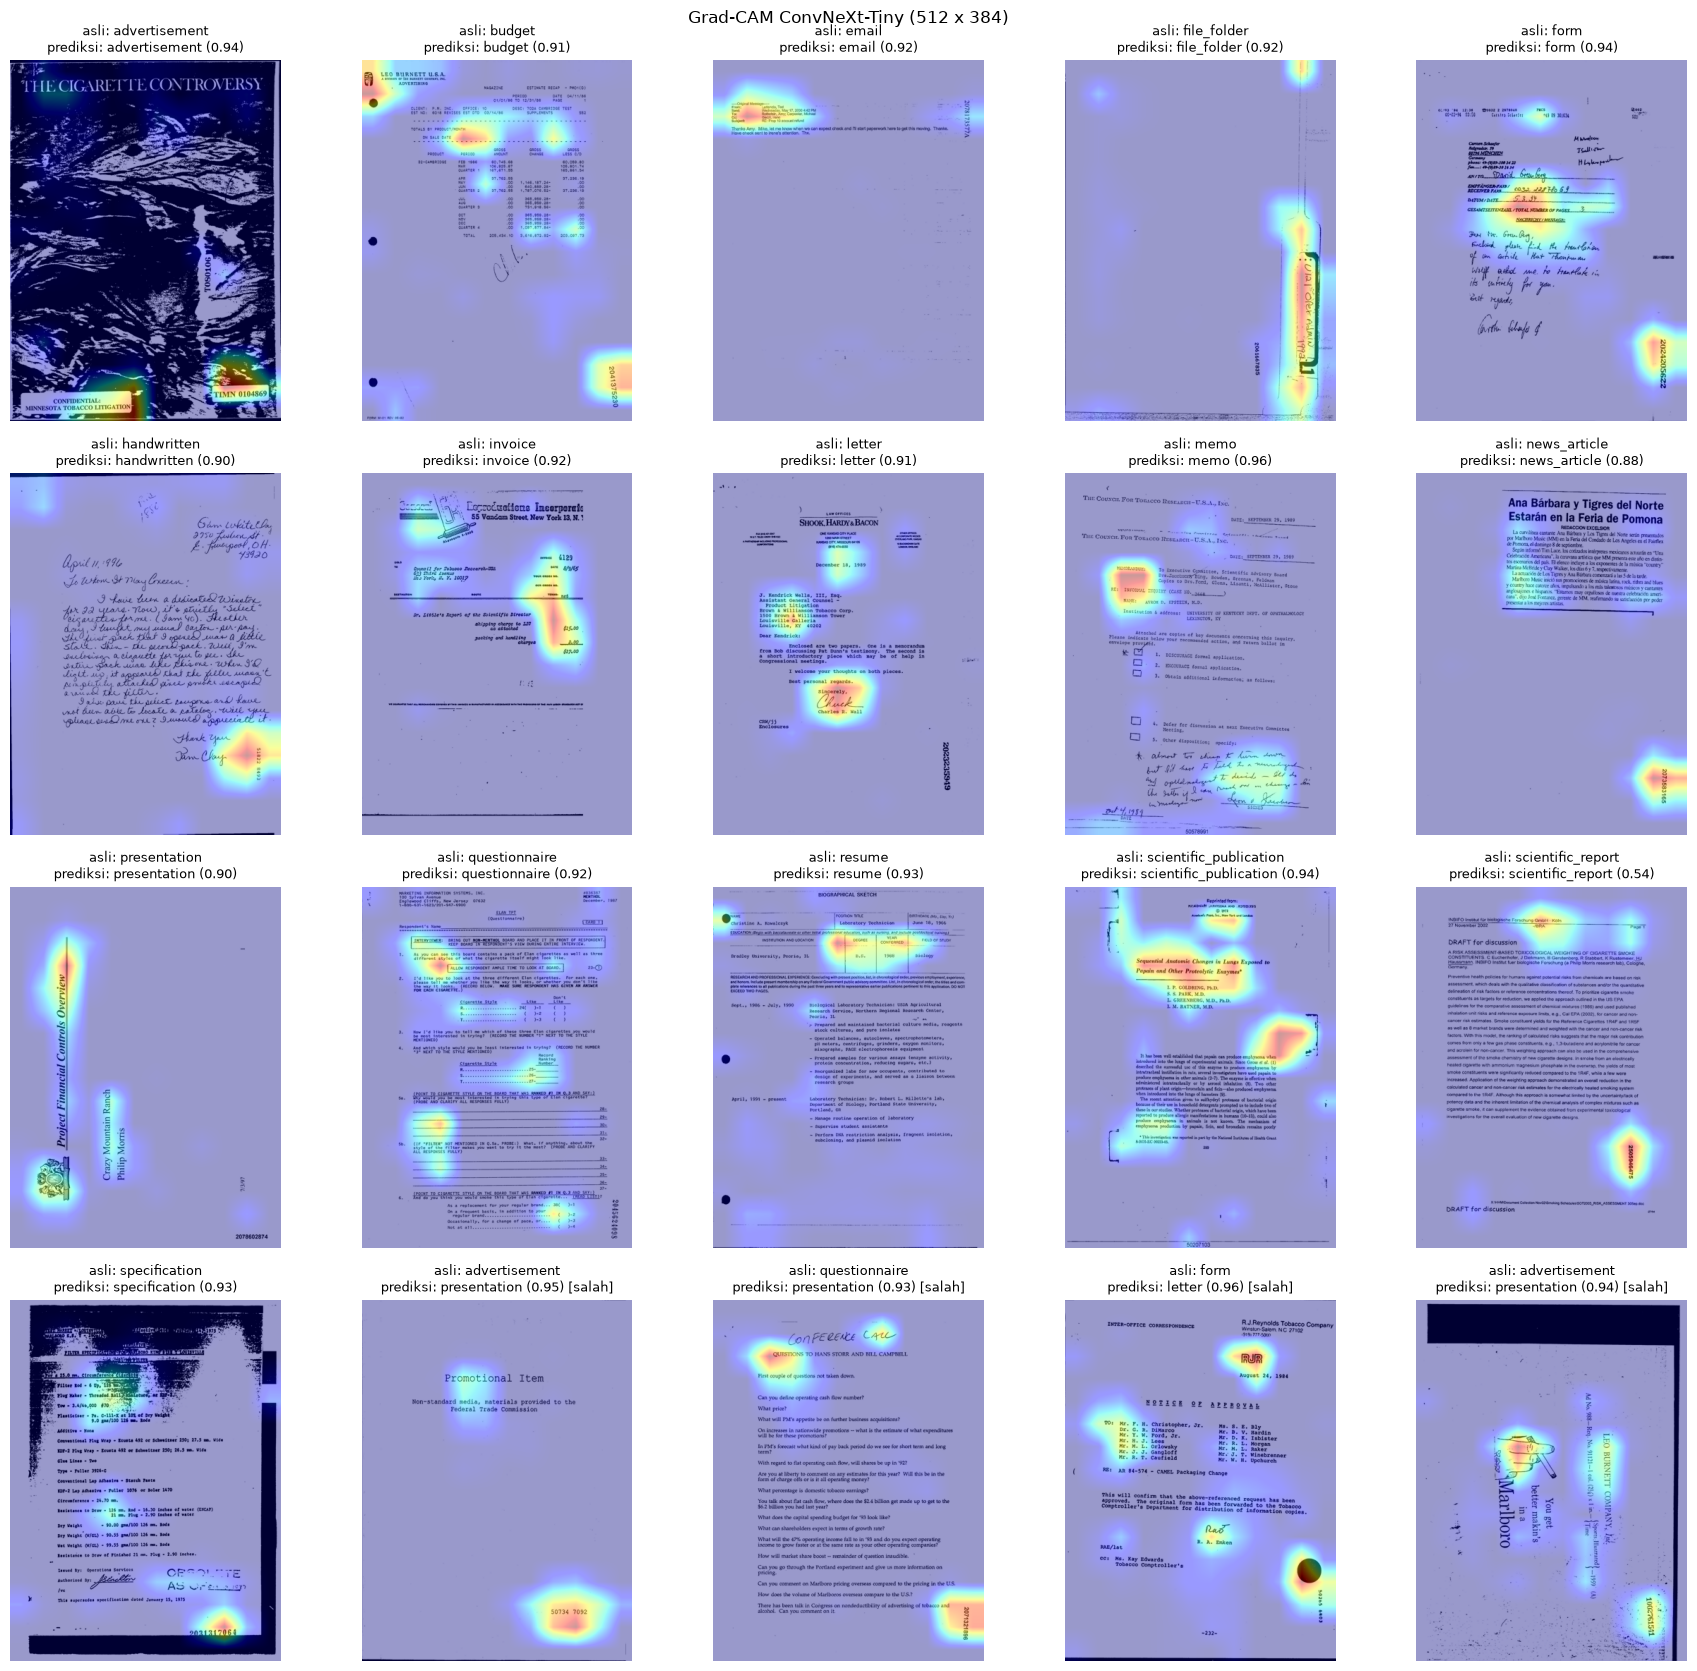

In [13]:
ckpt_path = Path("checkpoint") / f"{CAM_MODEL}_best.pth"
if ckpt_path.exists():
    model, cfg = load_checkpoint(ckpt_path, "cpu")
    cam = GradCAM(model, get_target_layer(model))
    tfm = get_eval_transforms(cfg["img_size"])
    sample = pred[pred["benar"]].groupby("label").head(1).sort_values("label")
    sample = pd.concat([sample, wrong.head(4)])

    fig, axes = plt.subplots(4, 5, figsize=(18, 17))
    for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
        with Image.open(r["path"]) as im:
            img = im.convert("RGB")
        heat, cls, p = cam(tfm(img).unsqueeze(0))
        h, w = to_hw(cfg["img_size"])
        ax.imshow(img.resize((w, h)))
        ax.imshow(heat, cmap="jet", alpha=0.4)
        tag = "" if r["benar"] else " [salah]"
        ax.set_title(f"asli: {CLASS_NAMES[r['label']]}\nprediksi: {CLASS_NAMES[cls]} ({p:.2f}){tag}", fontsize=9)
        ax.axis("off")
    for ax in axes.ravel()[len(sample):]:
        ax.axis("off")
    plt.suptitle("Grad-CAM ConvNeXt-Tiny (512 x 384)")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "gradcam_examples.png", dpi=120, bbox_inches="tight")
    plt.show()
    cam.remove()
else:
    print(f"Checkpoint {ckpt_path} tidak ditemukan, Grad-CAM dilewati.")

## 7. Skor Kaggle

| Submission | Val accuracy | Public | Private |
|---|---|---|---|
| baseline_resnet18 | 0,8285 | 0,81472 | |
| convnext_tiny_384 | 0,8867 | 0,87703 | |
| convnext_tiny_512 | 0,8833 | 0,88205 | |
| ensemble | 0,8924 | 0,89042 | |

Selisih skor public dan akurasi validation kurang dari 1,2 poin untuk semua submission, dan ensemble menjadi yang terbaik pada keduanya. Eksperimen 2 dan 3 bertukar urutan (validation 0,8867 vs 0,8833; public 0,87703 vs 0,88205), tetapi selisihnya kecil. Submission final yang dipilih adalah ensemble.

## 8. Kesimpulan

- Akurasi validation ensemble 0,8924, naik 6,4 poin dari baseline ResNet-18 (0,8285). Seluruh kelas membaik, dengan kenaikan F1 terbesar pada budget, form, dan scientific_report.
- Kelas termudah adalah email (F1 0,995), resume, handwritten, dan memo, yang memiliki penanda visual konsisten seperti blok header atau tulisan tangan.
- Kelas tersulit adalah form (0,757), scientific_report (0,783), presentation, dan questionnaire. Pasangan yang paling sering tertukar adalah invoice → form, scientific_report → presentation, dan news_article → presentation.
- Probabilitas prediksi cukup dapat dipercaya. Prediksi dengan probabilitas > 0,9 mencakup 61% data dengan akurasi 98,8%, sedangkan prediksi dengan probabilitas ≤ 0,5 hanya benar 39%.
- Sebagian kesalahan dengan keyakinan tinggi berasal dari dokumen yang ambigu, misalnya advertisement berisi judul pendek yang menyerupai slide presentation.
- Grad-CAM menunjukkan model memperhatikan header, tabel, dan tanda tangan, tetapi pada beberapa gambar juga memperhatikan nomor arsip di pojok kanan bawah. Pola ini berpotensi menjadi jalan pintas dan perlu diperiksa lebih lanjut.